# WideResNet50_2 + DPMM: Anomaly Detection

Same DPMM pipeline as `Dino-DPMM-anomaly-detection.ipynb` but with **WideResNet50_2** (torchvision) as the feature backbone instead of DINOv2.

Purpose: direct apples-to-apples comparison — self-supervised ViT patch features vs supervised CNN feature maps.

| | DINOv2 ViT-S/14 | WideResNet50_2 |
|---|---|---|
| Pretraining | Self-supervised (DINO) | Supervised (ImageNet) |
| Patch source | Transformer patch tokens | `layer3` spatial feature map |
| Patches / image @ 448 px | 32×32 = 1024 | 28×28 = 784 |
| Embedding dim | 384 | 1024 |
| Available without internet | No (torch.hub) | Yes (torchvision) |

In [27]:
!pip install -q pydicom

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cpu":
    print("WARNING: No GPU detected. Go to Runtime > Change runtime type > T4 GPU")

Using device: cuda


In [28]:
import os
from google.colab import drive

EXTRACT_DIR = "dataset"
GRID_DIR = os.path.join(EXTRACT_DIR, "grid")

if os.path.exists(GRID_DIR):
    print(f"Dataset already present at: {GRID_DIR}")
else:
    drive.mount("/content/drive")
    DRIVE_GRID_PATH = "/content/drive/MyDrive/coding/ML/datasets/mvtect/grid"  # <-- adjust this
    if not os.path.exists(DRIVE_GRID_PATH):
        raise FileNotFoundError(
            f"Could not find dataset at: {DRIVE_GRID_PATH}\n"
            "Upload your local grid/ folder to Google Drive, then update DRIVE_GRID_PATH above."
        )
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    os.symlink(DRIVE_GRID_PATH, GRID_DIR)
    print(f"Linked Drive dataset \u2192 {GRID_DIR}")

train_good = os.path.join(GRID_DIR, "train", "good")
n_train = len([f for f in os.listdir(train_good) if f.endswith(".png")])
print(f"Training images (normal): {n_train}  (expected: 264)")
test_categories = sorted(os.listdir(os.path.join(GRID_DIR, "test")))
print(f"Test categories: {test_categories}")

Dataset already present at: dataset/grid
Training images (normal): 264  (expected: 264)
Test categories: ['bent', 'broken', 'glue', 'good', 'metal_contamination', 'thread']


In [29]:
import numpy as np
import cv2
import torchvision.transforms as T
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

try:
    from pydicom import dcmread
    DICOM_AVAILABLE = True
except ImportError:
    DICOM_AVAILABLE = False
    print("pydicom not available — DICOM files will not load.")


class IndustrialAnomalyDataset(Dataset):
    def __init__(self, base_path, target_size=448):
        self.base_path = Path(base_path)
        self.target_size = target_size
        self.filepaths = []
        self.labels = []
        for f in self.base_path.rglob("*"):
            if f.is_file() and f.suffix.upper() in [".DCM", ".PNG", ".JPG", ".JPEG"]:
                self.filepaths.append(f)
                self.labels.append(f.relative_to(self.base_path).parts[0])
        self.normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.filepaths)

    def preprocess_image(self, img_raw, is_dcm=False):
        img_float = img_raw.astype(np.float32)
        if is_dcm:
            p_low, p_high = np.percentile(img_float, (1.0, 99.0))
            if p_high <= p_low:
                p_high = p_low + 1e-6
            image = np.clip(img_float, p_low, p_high)
            image = (image - p_low) / (p_high - p_low)
        else:
            image = img_float / 255.0
        ch, cw = image.shape[:2]
        scale = self.target_size / max(ch, cw)
        new_w, new_h = int(cw * scale), int(ch * scale)
        resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)
        canvas = np.zeros((self.target_size, self.target_size), dtype=np.float32)
        x_off = (self.target_size - new_w) // 2
        y_off = (self.target_size - new_h) // 2
        canvas[y_off:y_off + new_h, x_off:x_off + new_w] = resized
        img_tensor = torch.from_numpy(canvas).unsqueeze(0).repeat(3, 1, 1)
        img_tensor = self.normalize(img_tensor)
        return img_tensor, canvas

    def __getitem__(self, index):
        path = self.filepaths[index]
        label = self.labels[index]
        is_dcm = path.suffix.upper() == ".DCM"
        if is_dcm:
            img_raw = dcmread(path).pixel_array
        else:
            img_raw = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
            if img_raw is None:
                raise RuntimeError(f"Failed to read image: {path}")
        img_tensor, canvas = self.preprocess_image(img_raw, is_dcm=is_dcm)
        return img_tensor, label, str(path), canvas

In [30]:
TARGET_SIZE = 448
TRAIN_PATH = os.path.join(GRID_DIR, "train")
TEST_PATH  = os.path.join(GRID_DIR, "test")

train_dataset = IndustrialAnomalyDataset(TRAIN_PATH, target_size=TARGET_SIZE)
test_dataset  = IndustrialAnomalyDataset(TEST_PATH,  target_size=TARGET_SIZE)

print(f"Train samples: {len(train_dataset)}  (all 'good')")
print(f"Test samples:  {len(test_dataset)}")
print(f"Test label categories: {sorted(set(test_dataset.labels))}")

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=1, shuffle=False)

Train samples: 264  (all 'good')
Test samples:  78
Test label categories: ['bent', 'broken', 'glue', 'good', 'metal_contamination', 'thread']


## Feature Extractor: WideResNet50_2 layer3

WideResNet50_2 downsamples the input 16× by `layer3`, giving a spatial feature map of shape `[B, 1024, 28, 28]` for a 448×448 input.
Each of the 28×28 = **784 spatial positions** is treated as a patch embedding (analogous to DINOv2 patch tokens).

We use `layer3` rather than `layer4` to retain more spatial resolution (28×28 vs 14×14).

In [31]:
import torchvision
import torch.nn.functional as F

print("Loading WideResNet50_2 (torchvision, IMAGENET1K_V2 weights)...")
backbone = torchvision.models.wide_resnet50_2(
    weights=torchvision.models.Wide_ResNet50_2_Weights.IMAGENET1K_V2
)

# Truncate after layer3 to preserve spatial structure
feature_extractor = torch.nn.Sequential(
    backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
    backbone.layer1, backbone.layer2, backbone.layer3
)
feature_extractor = feature_extractor.to(device).eval()

# Verify output shape with a dummy forward pass
with torch.no_grad():
    dummy = torch.zeros(1, 3, TARGET_SIZE, TARGET_SIZE, device=device)
    feat_map = feature_extractor(dummy)  # [1, C, H, W]
    EMBED_DIM = feat_map.shape[1]
    GRID_DIM  = feat_map.shape[2]
    N_PATCHES = GRID_DIM * GRID_DIM

print(f"Feature map shape : {tuple(feat_map.shape)}")
print(f"Patch grid        : {GRID_DIM}\u00d7{GRID_DIM} = {N_PATCHES} patches per image")
print(f"Embedding dim     : {EMBED_DIM}")

Loading WideResNet50_2 (torchvision, IMAGENET1K_V2 weights)...
Downloading: "https://download.pytorch.org/models/wide_resnet50_2-9ba9bcbe.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-9ba9bcbe.pth


100%|██████████| 263M/263M [00:01<00:00, 168MB/s]  


Feature map shape : (1, 1024, 28, 28)
Patch grid        : 28×28 = 784 patches per image
Embedding dim     : 1024


In [32]:
all_features = []
total_batches = len(train_loader)
print(f"Extracting features from {len(train_dataset)} training images ({total_batches} batches)...")

with torch.no_grad():
    for i, (imgs, _, _, _) in enumerate(train_loader):
        imgs = imgs.to(device)
        feat_map = feature_extractor(imgs)          # [B, EMBED_DIM, GRID_DIM, GRID_DIM]
        B, C, H, W = feat_map.shape
        patches = feat_map.permute(0, 2, 3, 1).reshape(B * H * W, C)  # [B*H*W, C]
        patches = F.normalize(patches, p=2, dim=-1)
        all_features.append(patches.cpu().numpy())
        if (i + 1) % 5 == 0 or (i + 1) == total_batches:
            print(f"  Batch {i+1}/{total_batches}")

normal_features = np.concatenate(all_features, axis=0)
print(f"\nFeature matrix shape: {normal_features.shape}")
print(f"  = {len(train_dataset)} images \u00d7 {N_PATCHES} patches = {len(train_dataset)*N_PATCHES} total patches")

Extracting features from 264 training images (33 batches)...
  Batch 5/33
  Batch 10/33
  Batch 15/33
  Batch 20/33
  Batch 25/33
  Batch 30/33
  Batch 33/33

Feature matrix shape: (206976, 1024)
  = 264 images × 784 patches = 206976 total patches


In [33]:
from sklearn.mixture import BayesianGaussianMixture

print(f"Fitting variational DP-GMM on all {len(normal_features):,} patches...")
dpmm = BayesianGaussianMixture(
    n_components=50,
    covariance_type="diag",
    weight_concentration_prior=1e-3,
    max_iter=50,
    random_state=42,
)
dpmm.fit(normal_features)

active_mask = dpmm.weights_ > 0.01
centroids = dpmm.means_[active_mask]
print(f"\nConverged. Active components: {len(centroids)} / 50")
print(f"Centroid matrix: {centroids.shape}  [K_active, {EMBED_DIM}]")

centroids_tensor = torch.from_numpy(centroids.astype(np.float32)).to(device)

Fitting variational DP-GMM on all 206,976 patches...


/usr/local/lib/python3.12/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(



Converged. Active components: 50 / 50
Centroid matrix: (50, 1024)  [K_active, 1024]


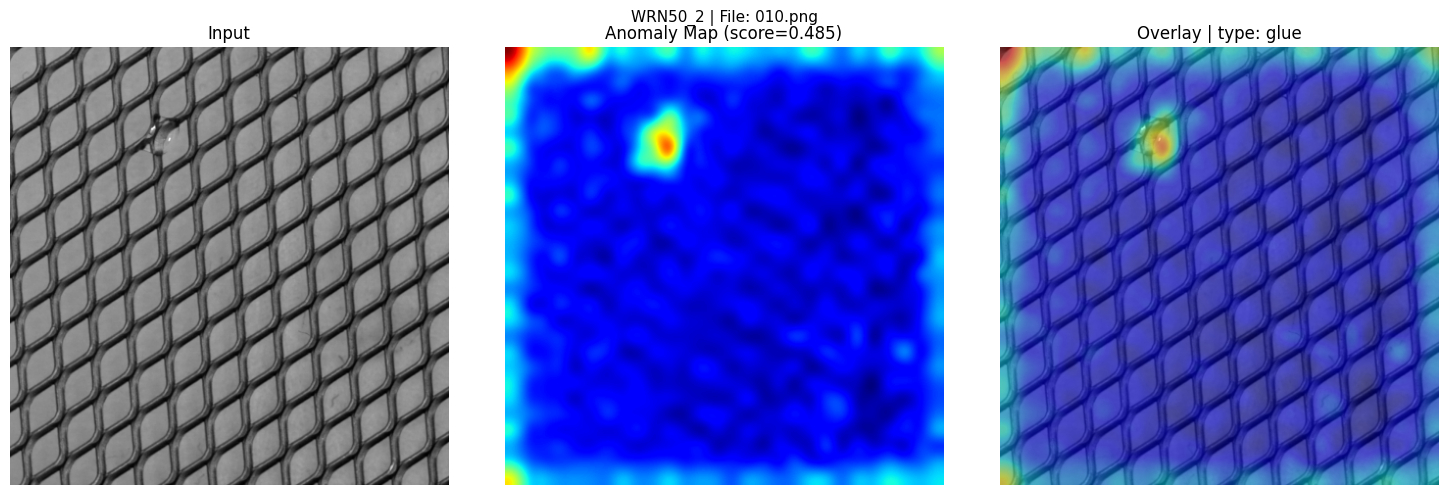

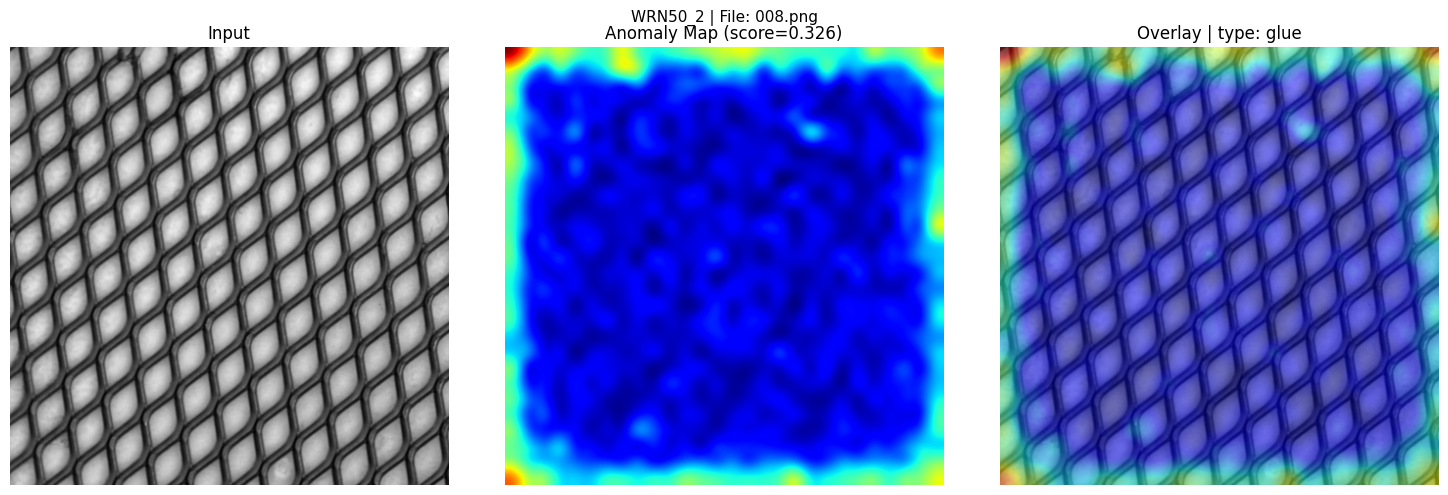

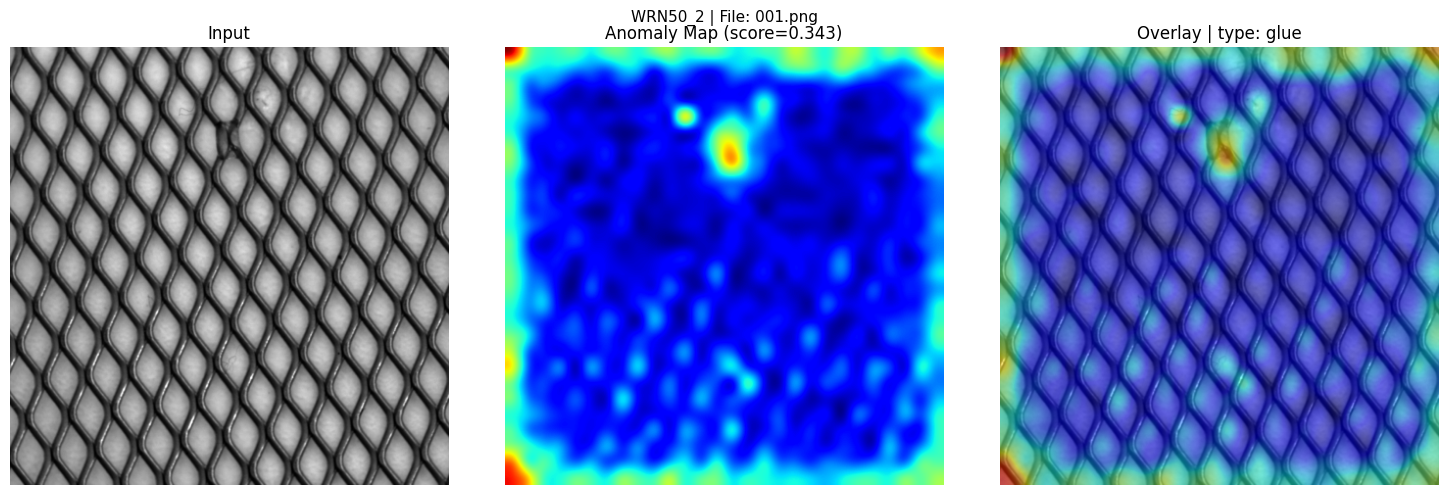

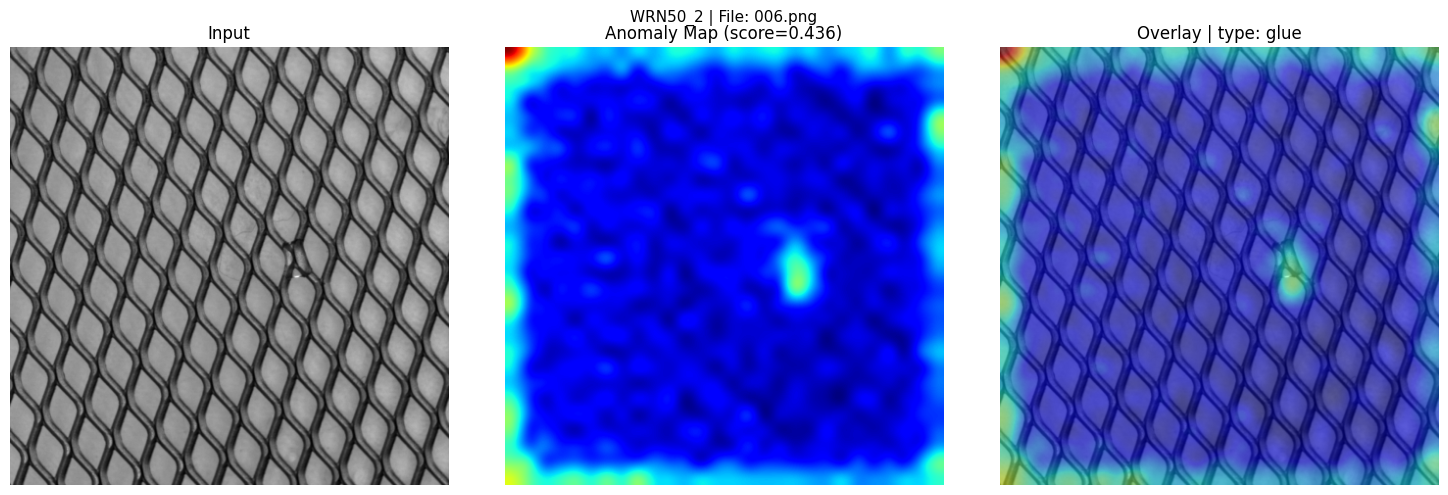

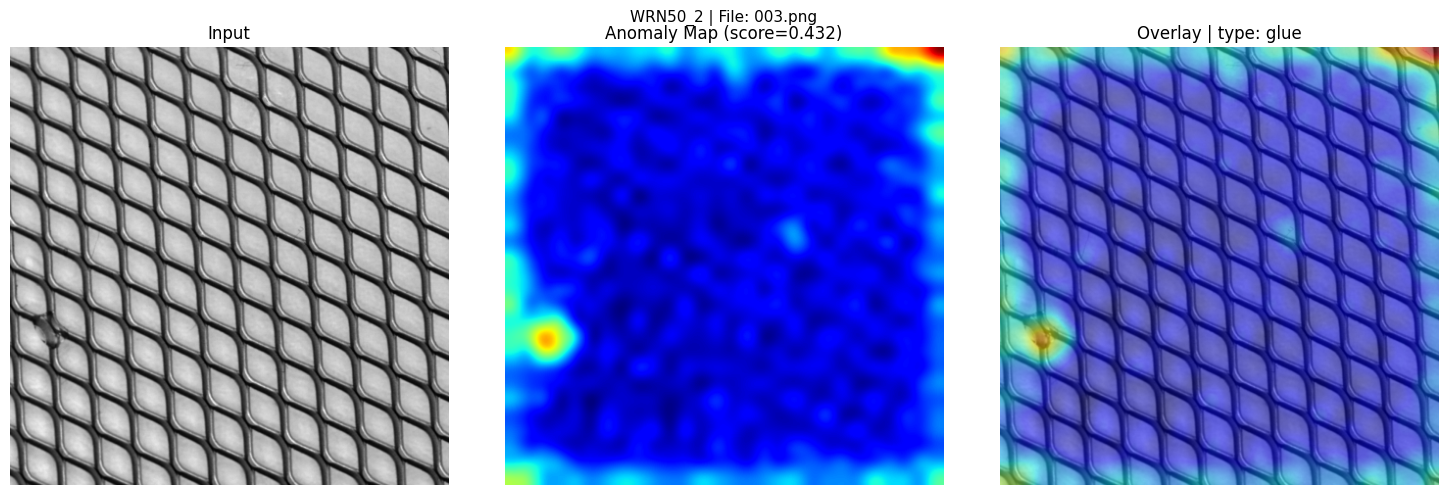


Saved 5 anomaly heatmaps to figures_wrn/


In [34]:
import matplotlib.pyplot as plt

os.makedirs("figures_wrn", exist_ok=True)
TEST_LIMIT = 5
visualized = 0

with torch.no_grad():
    for imgs, labels, paths, canvases in test_loader:
        if visualized >= TEST_LIMIT:
            break
        label = labels[0]
        if label == "good":
            continue
        imgs = imgs.to(device)
        feat_map = feature_extractor(imgs)
        B, C, H, W = feat_map.shape
        feats = feat_map.permute(0, 2, 3, 1).reshape(H * W, C)
        feats = F.normalize(feats, p=2, dim=-1)
        cos_sim = torch.matmul(feats, centroids_tensor.T)
        min_dist, _ = torch.min(1.0 - cos_sim, dim=-1)
        image_score = torch.max(min_dist).item()
        anomaly_map = min_dist.reshape(1, 1, GRID_DIM, GRID_DIM)
        anomaly_map = F.interpolate(
            anomaly_map, size=(TARGET_SIZE, TARGET_SIZE),
            mode="bicubic", align_corners=False
        ).squeeze().cpu().numpy()
        anomaly_map = cv2.GaussianBlur(anomaly_map, (15, 15), 0)
        canvas = canvases[0].numpy()
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
        ax1.imshow(canvas, cmap="gray"); ax1.set_title("Input"); ax1.axis("off")
        ax2.imshow(anomaly_map, cmap="jet")
        ax2.set_title(f"Anomaly Map (score={image_score:.3f})"); ax2.axis("off")
        ax3.imshow(canvas, cmap="gray")
        ax3.imshow(anomaly_map, cmap="jet", alpha=0.5)
        ax3.set_title(f"Overlay | type: {label}"); ax3.axis("off")
        fig.suptitle(f"WRN50_2 | File: {os.path.basename(paths[0])}", fontsize=11)
        plt.tight_layout()
        plt.savefig(f"figures_wrn/defect_{visualized}.png", dpi=150)
        plt.show()
        visualized += 1

print(f"\nSaved {visualized} anomaly heatmaps to figures_wrn/")

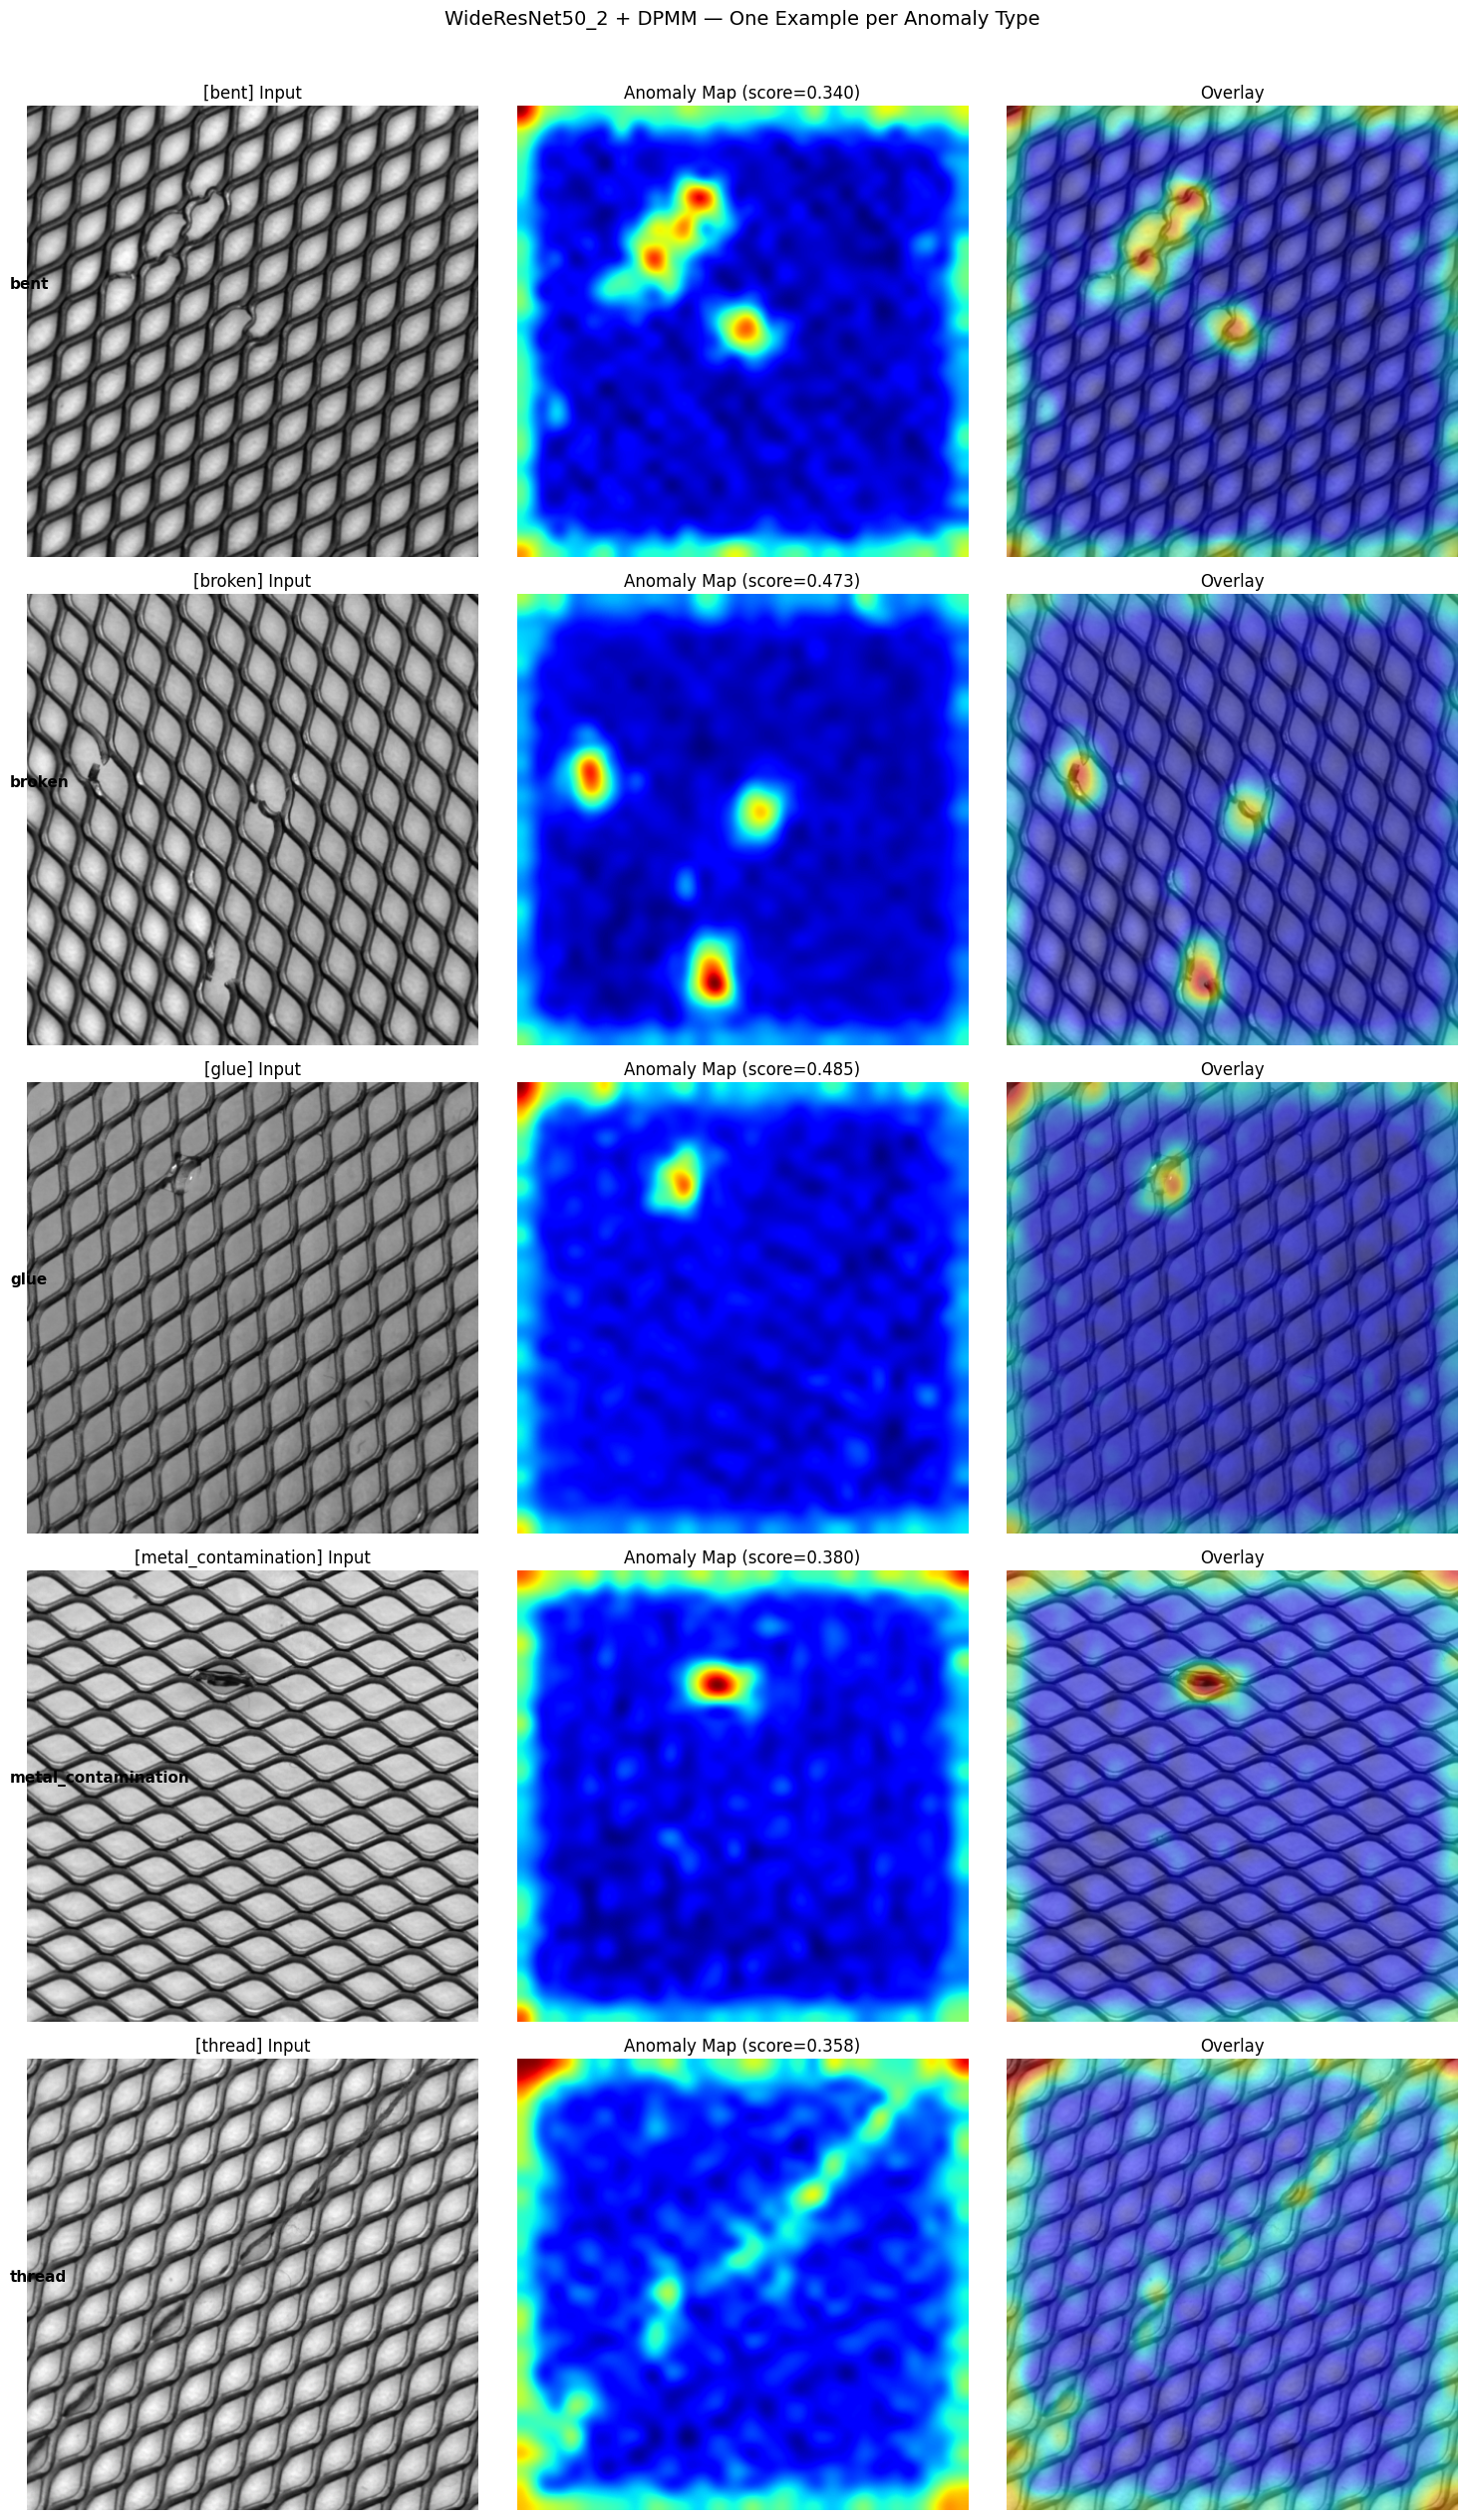

Saved → figures_wrn/all_anomaly_types.png


In [35]:
from collections import defaultdict

ANOMALY_CATEGORIES = [cat for cat in sorted(set(test_dataset.labels)) if cat != "good"]

examples = {}
for imgs, labels, paths, canvases in test_loader:
    label = labels[0]
    if label in ANOMALY_CATEGORIES and label not in examples:
        examples[label] = (imgs, paths[0], canvases[0].numpy())
    if len(examples) == len(ANOMALY_CATEGORIES):
        break

n_cats = len(ANOMALY_CATEGORIES)
fig, axes = plt.subplots(n_cats, 3, figsize=(15, 5 * n_cats))

with torch.no_grad():
    for row, category in enumerate(sorted(examples.keys())):
        imgs, path, canvas = examples[category]
        imgs = imgs.to(device)
        feat_map = feature_extractor(imgs)
        B, C, H, W = feat_map.shape
        feats = feat_map.permute(0, 2, 3, 1).reshape(H * W, C)
        feats = F.normalize(feats, p=2, dim=-1)
        cos_sim = torch.matmul(feats, centroids_tensor.T)
        min_dist, _ = torch.min(1.0 - cos_sim, dim=-1)
        image_score = torch.max(min_dist).item()
        anomaly_map = min_dist.reshape(1, 1, GRID_DIM, GRID_DIM)
        anomaly_map = F.interpolate(
            anomaly_map, size=(TARGET_SIZE, TARGET_SIZE),
            mode="bicubic", align_corners=False
        ).squeeze().cpu().numpy()
        anomaly_map = cv2.GaussianBlur(anomaly_map, (15, 15), 0)
        ax1, ax2, ax3 = axes[row]
        ax1.imshow(canvas, cmap="gray"); ax1.set_title(f"[{category}] Input"); ax1.axis("off")
        ax2.imshow(anomaly_map, cmap="jet"); ax2.set_title(f"Anomaly Map (score={image_score:.3f})"); ax2.axis("off")
        ax3.imshow(canvas, cmap="gray"); ax3.imshow(anomaly_map, cmap="jet", alpha=0.5)
        ax3.set_title("Overlay"); ax3.axis("off")
        fig.text(0.01, 1 - (row + 0.5) / n_cats, category, va="center", ha="left",
                 fontsize=11, fontweight="bold", transform=fig.transFigure)

plt.suptitle("WideResNet50_2 + DPMM \u2014 One Example per Anomaly Type", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("figures_wrn/all_anomaly_types.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved \u2192 figures_wrn/all_anomaly_types.png")

  AUROC                    : 0.6642
  Average Precision (AP)   : 0.8700
  Best threshold (max-F1)  : 0.4764
  Precision @ best thr     : 0.7671
  Recall    @ best thr     : 0.9825
  F1        @ best thr     : 0.8615

Per-category mean anomaly score:
  Category               Mean score     N  Detected
  ----------------------  ----------  ----  --------
  bent                       0.5156    12    12/12
  broken                     0.5834    12    12/12
  glue                       0.5321    11    11/11
  good                       0.5173    21    17/21  (normal)
  metal_contamination        0.5532    11    10/11
  thread                     0.5538    11    11/11


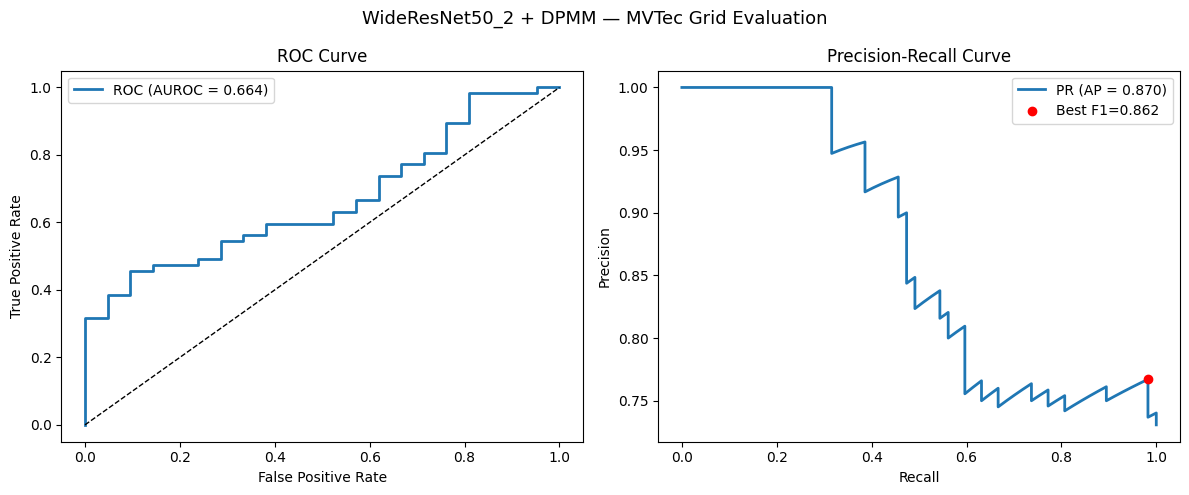

Saved → figures_wrn/evaluation_curves.png


In [36]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_fscore_support, roc_curve, precision_recall_curve,
)

all_scores, all_gt, all_cats = [], [], []

with torch.no_grad():
    for imgs, labels, paths, _ in test_loader:
        label = labels[0]
        imgs = imgs.to(device)
        feat_map = feature_extractor(imgs)
        B, C, H, W = feat_map.shape
        feats = feat_map.permute(0, 2, 3, 1).reshape(H * W, C)
        feats = F.normalize(feats, p=2, dim=-1)
        cos_sim = torch.matmul(feats, centroids_tensor.T)
        score = torch.max(1.0 - cos_sim).item()
        all_scores.append(score)
        all_gt.append(0 if label == "good" else 1)
        all_cats.append(label)

scores = np.array(all_scores)
gt     = np.array(all_gt)

# Save for cross-notebook comparison
np.save("figures_wrn/scores.npy", scores)
np.save("figures_wrn/gt.npy", gt)
np.save("figures_wrn/cats.npy", np.array(all_cats))

auroc = roc_auc_score(gt, scores)
ap    = average_precision_score(gt, scores)

prec_curve, rec_curve, thresholds_pr = precision_recall_curve(gt, scores)
f1_curve = 2 * prec_curve[:-1] * rec_curve[:-1] / (prec_curve[:-1] + rec_curve[:-1] + 1e-9)
best_idx = np.argmax(f1_curve)
best_thr = thresholds_pr[best_idx]
preds    = (scores >= best_thr).astype(int)
prec, rec, f1, _ = precision_recall_fscore_support(gt, preds, average="binary", zero_division=0)

print("=" * 52)
print(f"  AUROC                    : {auroc:.4f}")
print(f"  Average Precision (AP)   : {ap:.4f}")
print(f"  Best threshold (max-F1)  : {best_thr:.4f}")
print(f"  Precision @ best thr     : {prec:.4f}")
print(f"  Recall    @ best thr     : {rec:.4f}")
print(f"  F1        @ best thr     : {f1:.4f}")
print("=" * 52)

cat_scores = defaultdict(list)
for s, c in zip(scores, all_cats):
    cat_scores[c].append(s)

print("\nPer-category mean anomaly score:")
print(f"  {'Category':<22} {'Mean score':>10}  {'N':>4}  {'Detected':>8}")
print(f"  {'-'*22}  {'-'*10}  {'-'*4}  {'-'*8}")
for cat in sorted(cat_scores):
    cat_arr  = np.array(cat_scores[cat])
    detected = int((cat_arr >= best_thr).sum())
    marker   = "  (normal)" if cat == "good" else ""
    print(f"  {cat:<22} {cat_arr.mean():>10.4f}  {len(cat_arr):>4}  {detected:>4}/{len(cat_arr)}{marker}")

fpr, tpr, _ = roc_curve(gt, scores)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(fpr, tpr, lw=2, label=f"ROC (AUROC = {auroc:.3f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate")
ax1.set_title("ROC Curve"); ax1.legend()
ax2.plot(rec_curve, prec_curve, lw=2, label=f"PR (AP = {ap:.3f})")
ax2.scatter([rec_curve[best_idx]], [prec_curve[best_idx]],
            color="red", zorder=5, label=f"Best F1={f1:.3f}")
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
ax2.set_title("Precision-Recall Curve"); ax2.legend()
plt.suptitle("WideResNet50_2 + DPMM \u2014 MVTec Grid Evaluation", fontsize=13)
plt.tight_layout()
plt.savefig("figures_wrn/evaluation_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved \u2192 figures_wrn/evaluation_curves.png")

## Comparison: DINOv2 vs WideResNet50_2

Run this cell **after** also running `Dino-DPMM-anomaly-detection.ipynb` end-to-end (its metrics cell saves scores to `figures/`).

Both notebooks save `scores.npy`, `gt.npy`, and `cats.npy` for direct cross-model comparison.

Metric                     DINOv2 ViT-S/14    WideResNet50_2      Winner
------------------------------------------------------------------------
  AUROC                             0.8304            0.6642      DINOv2
  AP                                0.9299            0.8700      DINOv2
  PRECISION                         0.8235            0.7671      DINOv2
  RECALL                            0.9825            0.9825      DINOv2
  F1                                0.8960            0.8615      DINOv2


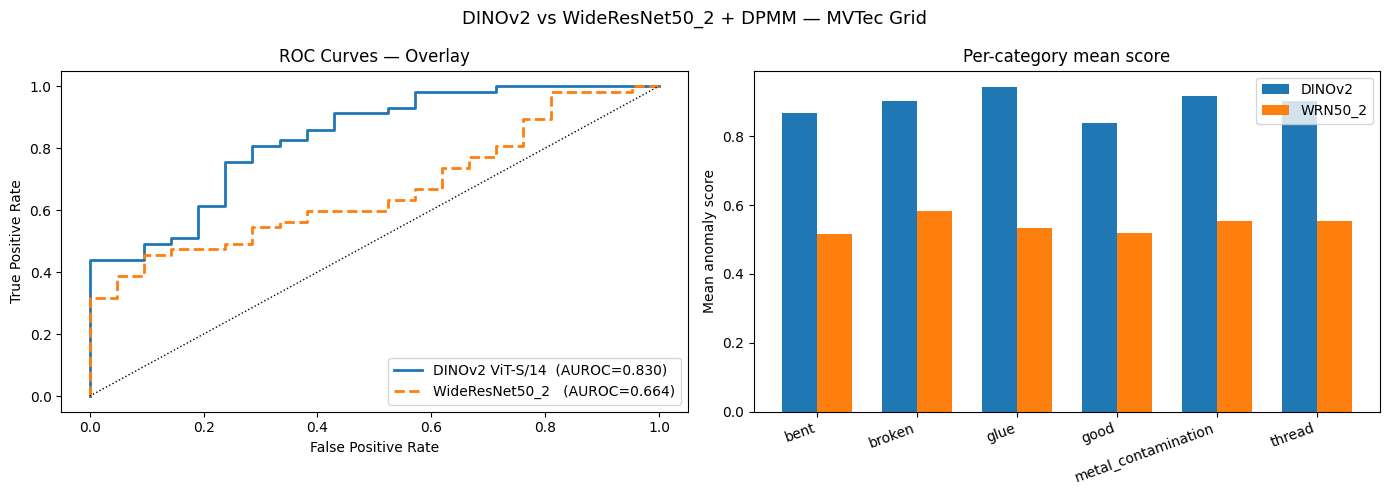

Saved → figures_wrn/comparison.png
Saved to Drive → /content/drive/MyDrive/anomaly_results/widresnet


In [38]:
DINO_DIR = "figures"      # saved by Dino-DPMM-anomaly-detection.ipynb
WRN_DIR  = "figures_wrn"  # saved by this notebook

dino_scores_path = os.path.join(DINO_DIR, "scores.npy")
if not os.path.exists(dino_scores_path):
    print("DINOv2 scores not found.")
    print("Run Dino-DPMM-anomaly-detection.ipynb through to the metrics cell first, then re-run this cell.")
else:
    dino_scores = np.load(os.path.join(DINO_DIR, "scores.npy"))
    dino_gt     = np.load(os.path.join(DINO_DIR, "gt.npy"))
    dino_cats   = np.load(os.path.join(DINO_DIR, "cats.npy"))
    wrn_scores  = np.load(os.path.join(WRN_DIR,  "scores.npy"))
    wrn_gt      = np.load(os.path.join(WRN_DIR,  "gt.npy"))
    wrn_cats    = np.load(os.path.join(WRN_DIR,  "cats.npy"))

    def compute_metrics(scores, gt):
        pc, rc, thr = precision_recall_curve(gt, scores)
        f1c = 2 * pc[:-1] * rc[:-1] / (pc[:-1] + rc[:-1] + 1e-9)
        idx = np.argmax(f1c)
        preds = (scores >= thr[idx]).astype(int)
        p, r, f, _ = precision_recall_fscore_support(gt, preds, average="binary", zero_division=0)
        return dict(
            auroc=roc_auc_score(gt, scores),
            ap=average_precision_score(gt, scores),
            precision=p, recall=r, f1=f,
        )

    dm = compute_metrics(dino_scores, dino_gt)
    wm = compute_metrics(wrn_scores,  wrn_gt)

    print(f"{'Metric':<25} {'DINOv2 ViT-S/14':>16}  {'WideResNet50_2':>16}  {'Winner':>10}")
    print("-" * 72)
    for key in ["auroc", "ap", "precision", "recall", "f1"]:
        winner = "DINOv2" if dm[key] >= wm[key] else "WRN50_2"
        print(f"  {key.upper():<23} {dm[key]:>16.4f}  {wm[key]:>16.4f}  {winner:>10}")

    # Overlay ROC curves
    fpr_d, tpr_d, _ = roc_curve(dino_gt, dino_scores)
    fpr_w, tpr_w, _ = roc_curve(wrn_gt,  wrn_scores)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(fpr_d, tpr_d, lw=2, label=f"DINOv2 ViT-S/14  (AUROC={dm['auroc']:.3f})")
    ax1.plot(fpr_w, tpr_w, lw=2, linestyle="--", label=f"WideResNet50_2   (AUROC={wm['auroc']:.3f})")
    ax1.plot([0, 1], [0, 1], "k:", lw=1)
    ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate")
    ax1.set_title("ROC Curves \u2014 Overlay"); ax1.legend()

    # Per-category mean score comparison
    cats = sorted(set(dino_cats))
    dino_means = [np.mean(dino_scores[dino_cats == c]) for c in cats]
    wrn_means  = [np.mean(wrn_scores[wrn_cats == c])   for c in cats]
    x = np.arange(len(cats))
    w = 0.35
    bars1 = ax2.bar(x - w/2, dino_means, w, label="DINOv2")
    bars2 = ax2.bar(x + w/2, wrn_means,  w, label="WRN50_2")
    ax2.set_xticks(x); ax2.set_xticklabels(cats, rotation=20, ha="right")
    ax2.set_ylabel("Mean anomaly score"); ax2.set_title("Per-category mean score")
    ax2.legend()

    plt.suptitle("DINOv2 vs WideResNet50_2 + DPMM \u2014 MVTec Grid", fontsize=13)
    plt.tight_layout()
    plt.savefig("figures_wrn/comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved \u2192 figures_wrn/comparison.png")
    import shutil
DRIVE_OUT = "/content/drive/MyDrive/anomaly_results/widresnet"
shutil.copytree("figures_wrn", DRIVE_OUT, dirs_exist_ok=True)
print(f"Saved to Drive → {DRIVE_OUT}")
